# 07 - Final Model Evaluation

## Objective

The objective of this notebook is to evaluate the selected machine learning model on the held-out test dataset.

Based on the cross-validation and feature engineering experiments conducted in the previous notebooks, we selected a Linear Support Vector Classifier (LinearSVC) with TF-IDF features and sublinear term frequency.

The test dataset will be used only for final evaluation. No further model tuning will be performed using its results.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from pathlib import Path

sns.set_theme(style="whitegrid")

In [3]:
train_df = pd.read_csv("../data/processed/train.csv")
test_df = pd.read_csv("../data/processed/test.csv")

X_train = train_df["text"]
y_train = train_df["target"]

X_test = test_df["text"]
y_test = test_df["target"]

print("Training dataset shape:", X_train.shape)
print("Test dataset shape:", X_test.shape)

print("\nTraining label distribution:")
print(y_train.value_counts().sort_index())

print("\nTest label distribution:")
print(y_test.value_counts().sort_index())

Training dataset shape: (32328,)
Test dataset shape: (8082,)

Training label distribution:
target
0    16172
1    16156
Name: count, dtype: int64

Test label distribution:
target
0    4043
1    4039
Name: count, dtype: int64


## Final Model

Based on the cross-validation and feature engineering experiments, the selected model is LinearSVC with TF-IDF vectorization.

Sublinear term frequency is enabled because it produced the best cross-validation performance among the feature configurations tested.

The model is now trained on the entire training dataset before being evaluated on the held-out test dataset.

In [4]:
final_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LinearSVC(random_state=42)
    )
])

In [5]:
final_model.fit(X_train, y_train)

print("Final model trained successfully.")

Final model trained successfully.


In [6]:
y_pred = final_model.predict(X_test)

# LinearSVC provides decision scores rather than probabilities
y_scores = final_model.decision_function(X_test)

print("Predictions generated successfully.")
print("Number of predictions:", len(y_pred))

Predictions generated successfully.
Number of predictions: 8082


## Evaluation Metrics

We evaluate the model using the following metrics:

- Accuracy: Overall proportion of correct predictions.
- Precision: Proportion of predicted positive (CG) reviews that are actually CG.
- Recall: Proportion of actual CG reviews correctly identified.
- F1-score: Harmonic mean of precision and recall.
- Macro F1-score: Average F1-score across both classes, treating them equally.
- Balanced Accuracy: Average recall across both classes.
- ROC-AUC: Measures how well the model separates the two classes across different decision thresholds.

In [7]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

macro_f1 = f1_score(y_test, y_pred, average="macro")
balanced_acc = balanced_accuracy_score(y_test, y_pred)

roc_auc = roc_auc_score(y_test, y_scores)

test_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision (CG)",
        "Recall (CG)",
        "F1-score (CG)",
        "Macro F1-score",
        "Balanced Accuracy",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        macro_f1,
        balanced_acc,
        roc_auc
    ]
})

test_metrics["Score"] = test_metrics["Score"].round(4)

test_metrics

,Metric,Score
0,Accuracy,0.9500
1,Precision (CG),0.9586
2,Recall (CG),0.9406
3,F1-score (CG),0.9495
4,Macro F1-score,0.9500
5,Balanced Accuracy,0.9500
6,ROC-AUC,0.9889


In [8]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["OR", "CG"],
        digits=4
    )
)

              precision    recall  f1-score   support

          OR     0.9417    0.9594    0.9505      4043
          CG     0.9586    0.9406    0.9495      4039

    accuracy                         0.9500      8082
   macro avg     0.9502    0.9500    0.9500      8082
weighted avg     0.9502    0.9500    0.9500      8082



## Confusion Matrix

A confusion matrix compares the actual labels with the model's predicted labels.

It helps us identify:
- True Negatives (TN): OR reviews correctly predicted as OR.
- False Positives (FP): OR reviews incorrectly predicted as CG.
- False Negatives (FN): CG reviews incorrectly predicted as OR.
- True Positives (TP): CG reviews correctly predicted as CG.

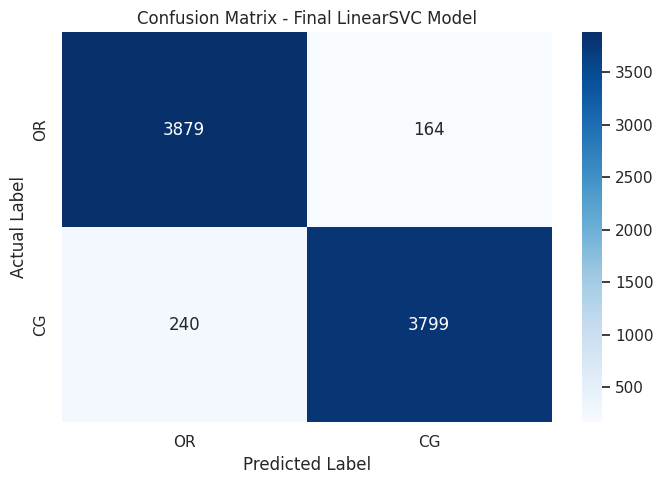

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["OR", "CG"],
    yticklabels=["OR", "CG"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Final LinearSVC Model")
plt.tight_layout()

plt.savefig(
    "../results/figures/final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives (OR correctly classified):", tn)
print("False Positives (OR incorrectly classified as CG):", fp)
print("False Negatives (CG incorrectly classified as OR):", fn)
print("True Positives (CG correctly classified):", tp)

print("\nTotal incorrect predictions:", fp + fn)

True Negatives (OR correctly classified): 3879
False Positives (OR incorrectly classified as CG): 164
False Negatives (CG incorrectly classified as OR): 240
True Positives (CG correctly classified): 3799

Total incorrect predictions: 404


## ROC Curve

The Receiver Operating Characteristic (ROC) curve illustrates the trade-off between:

- True Positive Rate (TPR): Proportion of actual CG reviews correctly identified.
- False Positive Rate (FPR): Proportion of actual OR reviews incorrectly classified as CG.

The Area Under the Curve (AUC) summarizes the model's ability to distinguish between the two classes. A higher AUC indicates better class separation.

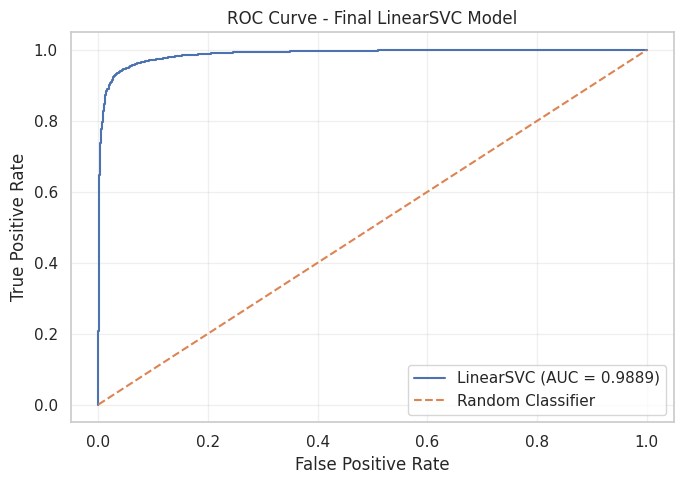

In [11]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_scores)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"LinearSVC (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Final LinearSVC Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/figures/final_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Cross-Validation vs Test Performance

We compare the model's average cross-validation performance on the training dataset with its final performance on the held-out test dataset.

A small difference between these results suggests that the model generalizes consistently to unseen samples.

In [13]:
cv_results = pd.read_csv(
    "../results/metrics/feature_experiment_results.csv"
)

# Select the Sublinear TF configuration
cv_best = cv_results[
    cv_results["Configuration"] == "Sublinear TF"
].iloc[0]

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro F1",
        "Balanced Accuracy",
        "ROC-AUC"
    ],
    "Cross-Validation": [
        cv_best["accuracy_mean"],
        cv_best["macro_f1_mean"],
        cv_best["balanced_accuracy_mean"],
        cv_best["roc_auc_mean"]
    ],
    "Test": [
        accuracy,
        macro_f1,
        balanced_acc,
        roc_auc
    ]
})

comparison["Difference"] = (
    comparison["Test"] - comparison["Cross-Validation"]
)

comparison.round(4)

,Metric,Cross-Validation,Test,Difference
0,Accuracy,0.9461,0.9500,0.0039
1,Macro F1,0.9461,0.9500,0.0039
2,Balanced Accuracy,0.9461,0.9500,0.0039
3,ROC-AUC,0.9875,0.9889,0.0014


In [14]:
# Save final test metrics
test_metrics.to_csv(
    "../results/metrics/final_test_metrics.csv",
    index=False
)

# Save cross-validation vs test comparison
comparison.to_csv(
    "../results/metrics/cv_vs_test_comparison.csv",
    index=False
)

print("Evaluation metrics saved successfully.")

Evaluation metrics saved successfully.


In [15]:
test_predictions = pd.DataFrame({
    "text": X_test,
    "actual": y_test,
    "predicted": y_pred,
    "decision_score": y_scores,
    "correct": y_test.to_numpy() == y_pred
})

test_predictions.to_csv(
    "../results/predictions/final_test_predictions.csv",
    index=False
)

print("Test predictions saved successfully.")
print("Number of predictions saved:", len(test_predictions))

Test predictions saved successfully.
Number of predictions saved: 8082


In [16]:
import joblib

joblib.dump(
    final_model,
    "../models/final_linear_svc_pipeline.joblib"
)

print("Final model saved successfully.")

Final model saved successfully.
